In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from transformers import AutoTokenizer

# Visual configuration
COMP_PALETTE = ["#4e79a7", "#f28e2b", "#59a14f", "#e15759", "#76b7b2"]
COMP_LABELS = ["C1", "C2", "C3", "C4", "C5"]
PRIMARY_CLR = "#2c7bb6"
SCORE_STEPS = [0, 40, 80, 120, 160, 200]

sns.set_theme(style="whitegrid", context="paper", font_scale=1.3)
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

SAVE = True # Set True to export PDFs
FIG_DIR = "figures_aesenem" # Choose the directory of the exportation
if SAVE:
    os.makedirs(FIG_DIR, exist_ok=True)

def _save(name):
    if SAVE:
        plt.savefig(f"{FIG_DIR}/{name}.pdf", bbox_inches="tight")

#### Load and Prepare the Data

In [2]:
print("Loading AES-ENEM dataset - JBCS2025 subset...")
dataset = load_dataset("kamel-usp/aes_enem_dataset", "JBCS2025")

# Load and tag every split
frames = {}
for split_name in ("train", "validation", "test"):
    frames[split_name] = dataset[split_name].to_pandas()
    frames[split_name]["split"] = split_name

df = pd.concat(frames.values(), ignore_index=True)

# Expand grades list [C1, C2, C3, C4, C5, Total] into separate columns
grades_df = pd.DataFrame(
    df["grades"].tolist(),
    index=df.index,
    columns=["C1", "C2", "C3", "C4", "C5", "Total_Score"],
)
df = pd.concat([df, grades_df], axis=1)

# Coerce types
for col in ["C1", "C2", "C3", "C4", "C5", "Total_Score"]:
    df[col] = df[col].astype(int)
df["essay_year"] = df["essay_year"].astype(int)

print(f"Loaded {len(df):,} essays  |  "
      + "  /  ".join(f"{k}: {len(v)}" for k, v in frames.items()))

Loading AES-ENEM dataset - JBCS2025 subset...
Loaded 770 essays  |  train: 500  /  validation: 132  /  test: 138


In [3]:
# Basic info and sanity check
print("Shape:", df.shape)
print("\nMissing values in key columns:")
key_cols = ["id", "id_prompt", "essay_year", "split"] + COMP_LABELS + ["Total_Score"]
print(df[key_cols].isnull().sum())
print("\nUnique score values per competency:")
for c in COMP_LABELS:
    print(f"  {c}: {sorted(df[c].unique())}")

Shape: (770, 15)

Missing values in key columns:
id             0
id_prompt      0
essay_year     0
split          0
C1             0
C2             0
C3             0
C4             0
C5             0
Total_Score    0
dtype: int64

Unique score values per competency:
  C1: [np.int64(0), np.int64(40), np.int64(80), np.int64(120), np.int64(160), np.int64(200)]
  C2: [np.int64(0), np.int64(40), np.int64(80), np.int64(120), np.int64(160), np.int64(200)]
  C3: [np.int64(0), np.int64(40), np.int64(80), np.int64(120), np.int64(160), np.int64(200)]
  C4: [np.int64(0), np.int64(40), np.int64(80), np.int64(120), np.int64(160), np.int64(200)]
  C5: [np.int64(0), np.int64(40), np.int64(80), np.int64(120), np.int64(160), np.int64(200)]


In [4]:
df[["id", "id_prompt", "essay_year", "split", "C1", "C2", "C3", "C4", "C5", "Total_Score"]].head(5)

,id,id_prompt,essay_year,split,C1,C2,C3,C4,C5,Total_Score
0,8.html,posse-de-armas-mais-seguranca-ou-mais-perigo,2019,train,160,120,120,120,80,600
1,0.html,a-ciencia-na-era-da-pos-verdade,2019,train,80,120,80,120,120,520
2,14.html,preservacao-da-amazonia-desafio-brasileiro-ou-...,2019,train,120,120,120,120,120,600
3,2.html,a-ciencia-na-era-da-pos-verdade,2019,train,120,120,160,160,120,680
4,1.html,universidade-em-crise-quem-paga-a-conta,2019,train,160,120,160,160,80,680


#### Descriptive statistics

In [5]:
score_cols = COMP_LABELS + ["Total_Score"]
stats = (
    df[score_cols]
    .describe()
    .T
    .rename(columns={
        "count": "N", "mean": "Mean", "std": "Std Dev",
        "min": "Min", "25%": "Q1", "50%": "Median", "75%": "Q3", "max": "Max",
    })
)
stats["N"] = stats["N"].astype(int)
stats = stats.round(2)
stats.index.name = "Metric"
stats

,N,Mean,Std Dev,Min,Q1,Median,Q3,Max
Metric,,,,,,,,
C1,770,141.14,33.33,0.0,120.0,160.0,160.0,200.0
C2,770,122.18,50.62,0.0,120.0,120.0,160.0,200.0
C3,770,118.49,47.84,0.0,80.0,120.0,160.0,200.0
C4,770,135.22,31.65,0.0,120.0,120.0,160.0,200.0
C5,770,78.23,59.31,0.0,40.0,80.0,120.0,200.0
Total_Score,770,595.27,163.63,0.0,480.0,600.0,720.0,1000.0


#### Number of essays per year

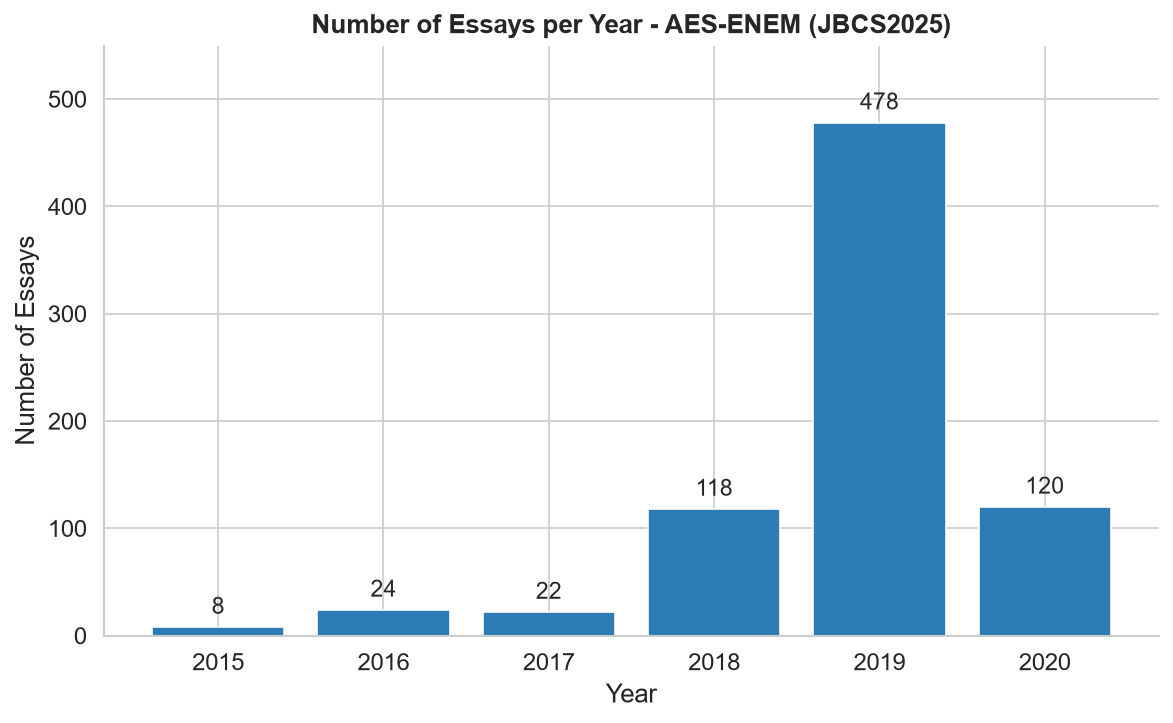

In [6]:
year_counts = df["essay_year"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(
    year_counts.index.astype(str), year_counts.values,
    color=PRIMARY_CLR, edgecolor="white", linewidth=0.8,
)
ax.bar_label(bars, padding=4, fontsize=11)
ax.set_title("Number of Essays per Year - AES-ENEM (JBCS2025)", fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("Number of Essays")
ax.set_ylim(0, year_counts.max() * 1.15)
plt.tight_layout()
_save("01_essays_per_year")
plt.show()

#### Number of essays per prompt

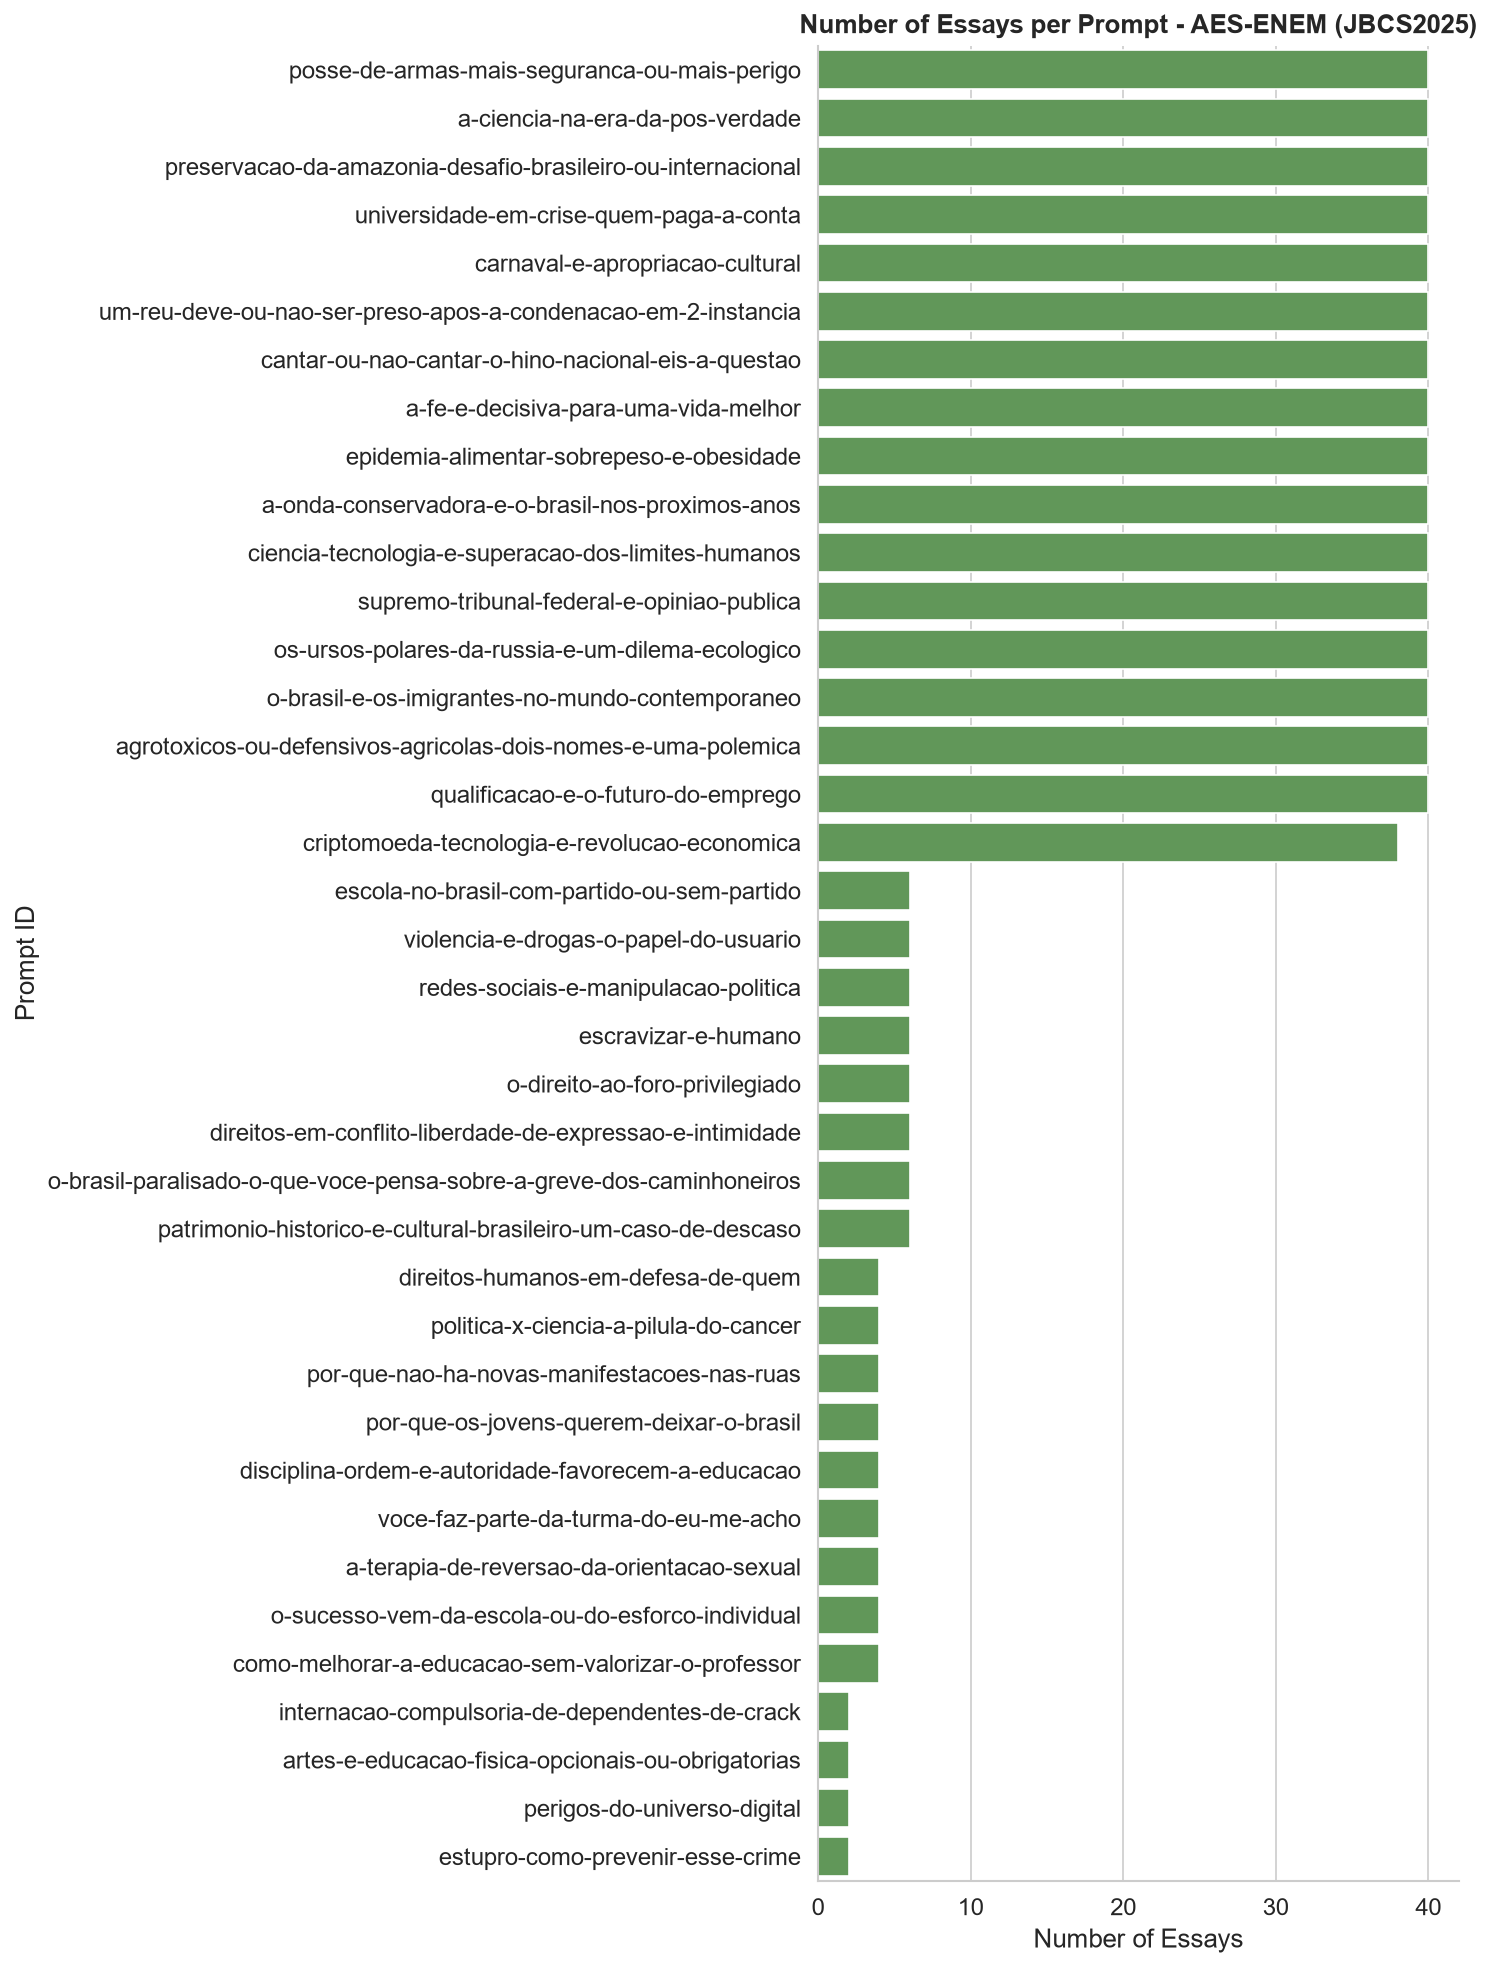

In [7]:
prompt_order = df["id_prompt"].value_counts().index.tolist()

fig, ax = plt.subplots(figsize=(10, max(5, len(prompt_order) * 0.35)))
sns.countplot(data=df, y="id_prompt", order=prompt_order, color=COMP_PALETTE[2], ax=ax)
ax.set_title("Number of Essays per Prompt - AES-ENEM (JBCS2025)", fontweight="bold")
ax.set_xlabel("Number of Essays")
ax.set_ylabel("Prompt ID")
plt.tight_layout()
_save("02_essays_per_prompt")
plt.show()

#### Number of essays per prompt per year

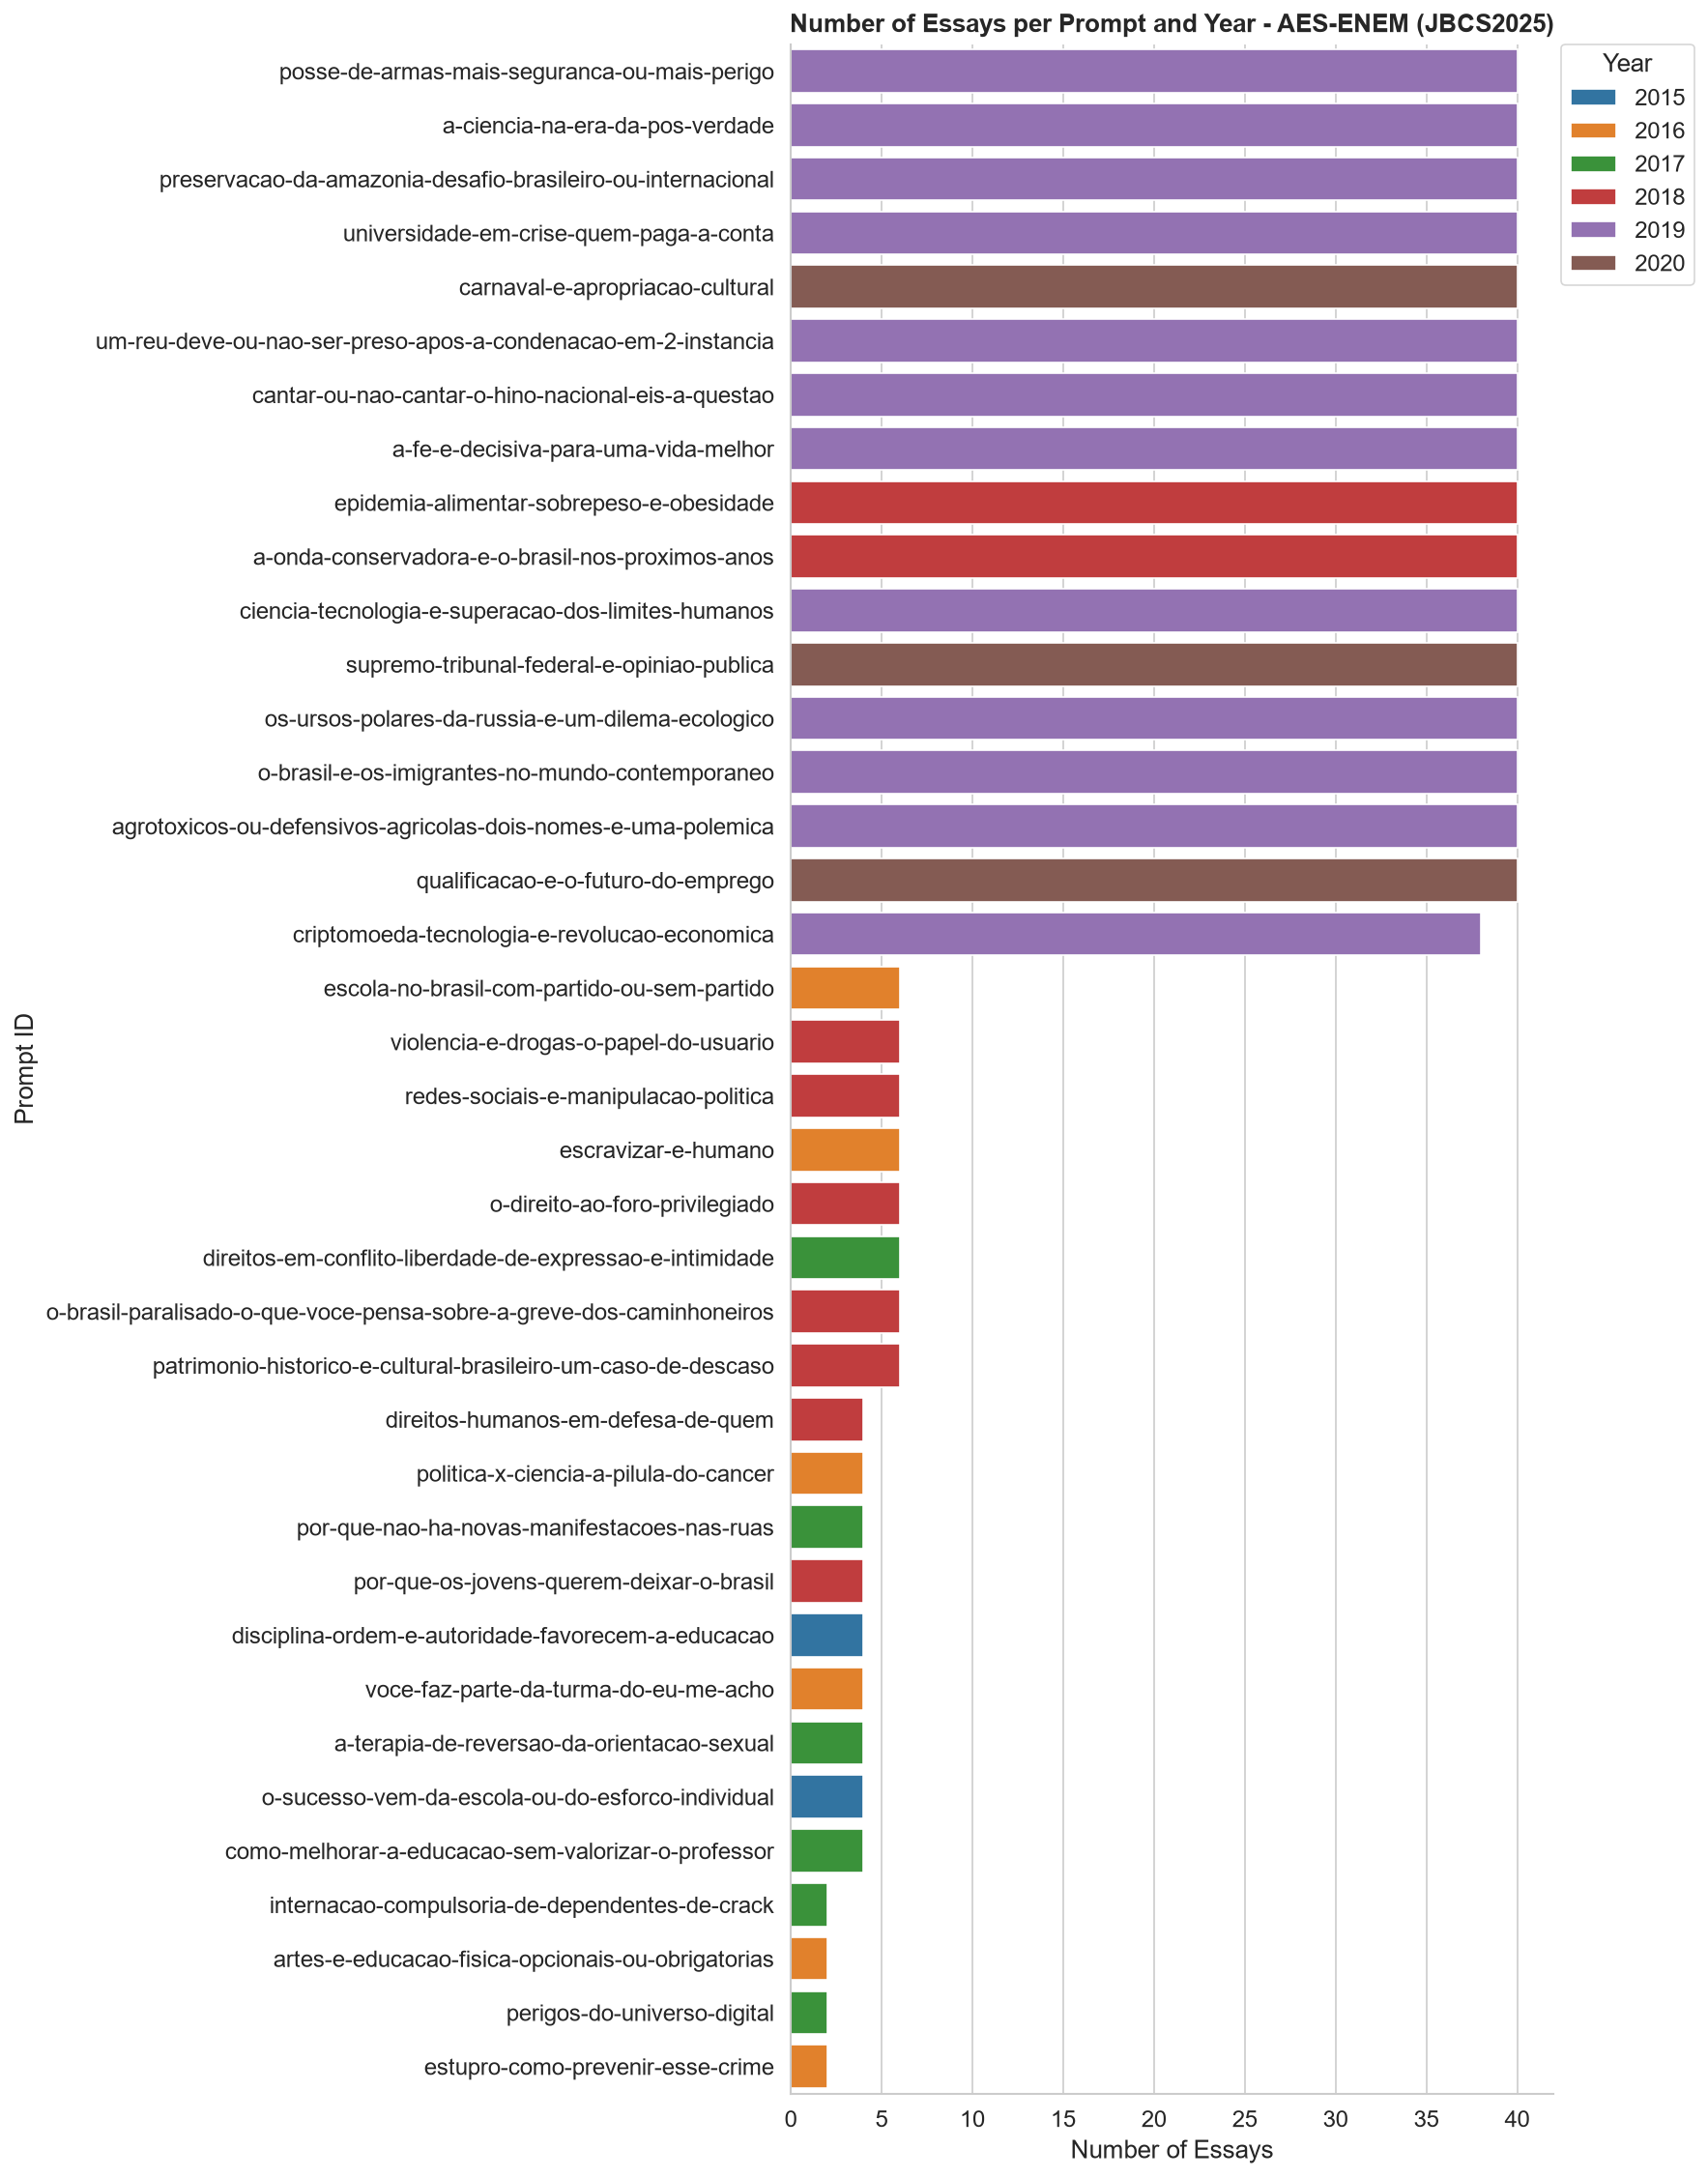

In [8]:
prompt_order = df["id_prompt"].value_counts().index.tolist()

fig, ax = plt.subplots(figsize=(12, max(6, len(prompt_order) * 0.40)))
sns.countplot(
    data=df, y="id_prompt", hue="essay_year",
    order=prompt_order, palette="tab10", ax=ax,
)
ax.set_title("Number of Essays per Prompt and Year - AES-ENEM (JBCS2025)",
             fontweight="bold")
ax.set_xlabel("Number of Essays")
ax.set_ylabel("Prompt ID")
ax.legend(title="Year", bbox_to_anchor=(1.01, 1), loc="upper left", borderaxespad=0)
plt.tight_layout()
_save("03_essays_per_prompt_year")
plt.show()

#### Distribution of scores by competency

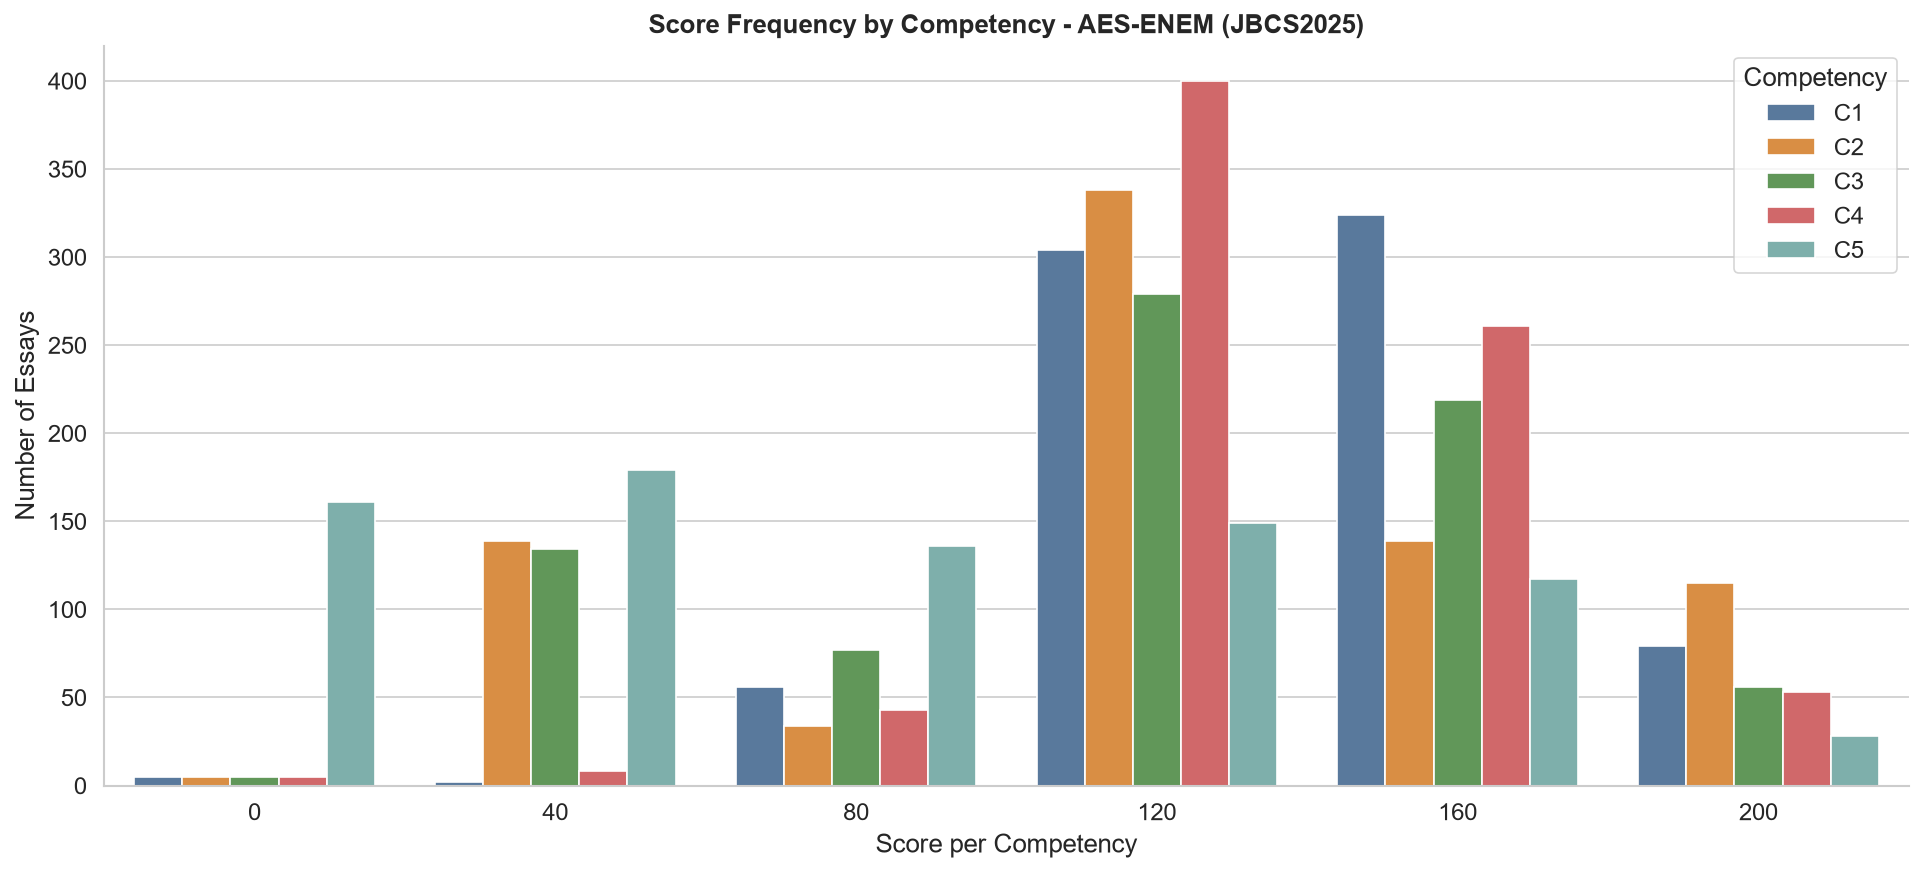

In [9]:
# Transform data to melted for Seaborn
df_melted = df.melt(
    value_vars=COMP_LABELS,
    var_name="Competency",
    value_name="Score",
)

# Grouped Bar Chat
fig, ax = plt.subplots(figsize=(13, 6))
sns.countplot(
    data=df_melted,
    x="Score",
    hue="Competency",
    order=SCORE_STEPS,
    palette=COMP_PALETTE,
    ax=ax,
)
ax.set_title("Score Frequency by Competency - AES-ENEM (JBCS2025)", fontweight="bold")
ax.set_xlabel("Score per Competency")
ax.set_ylabel("Number of Essays")
ax.legend(title="Competency", frameon=True)
plt.tight_layout()
_save("04a_score_freq_by_competency")
plt.show()

C:\Users\User\AppData\Local\Temp\ipykernel_18780\3091893865.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


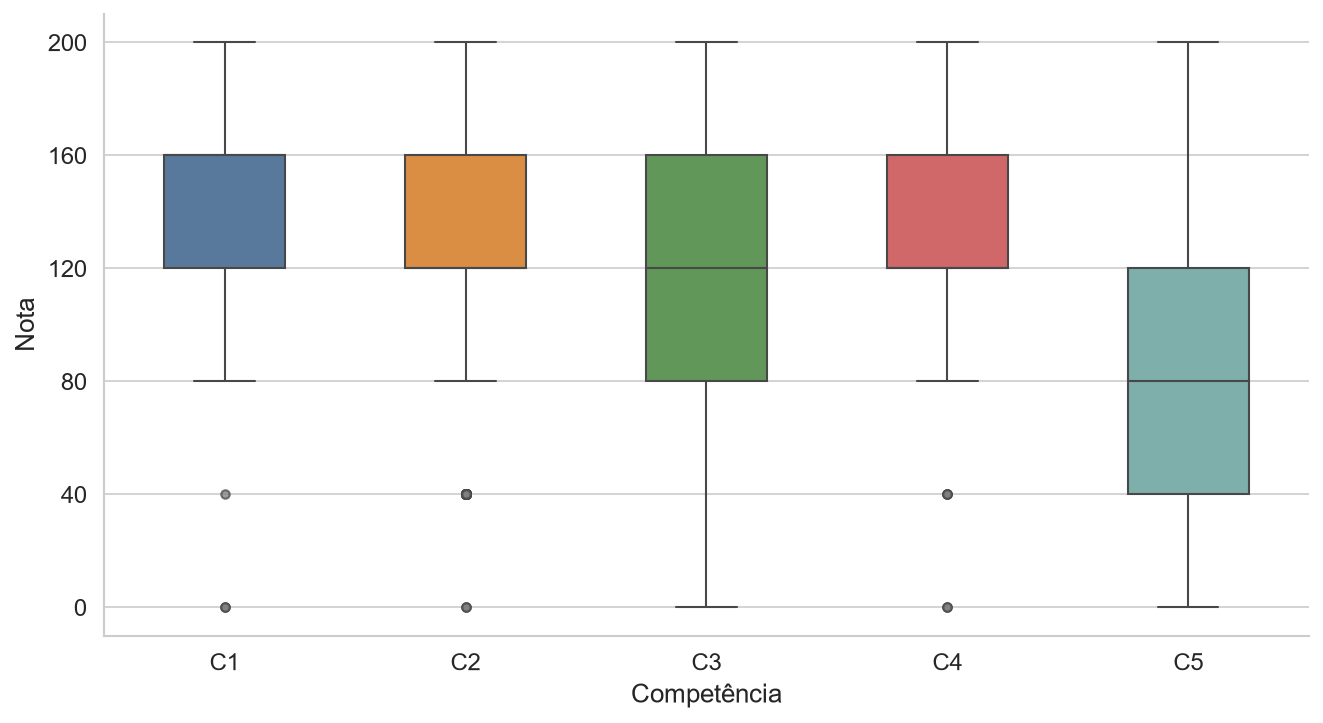

In [16]:
# Box Plot
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(
    data=df_melted,
    x="Competency",
    y="Score",
    order=COMP_LABELS,
    palette=COMP_PALETTE,
    width=0.5,
    flierprops=dict(marker="o", markerfacecolor="grey", markersize=4, alpha=0.5),
    ax=ax,
)
# ax.set_title("Score Spread by Competency - AES-ENEM (JBCS2025)", fontweight="bold")
ax.set_xlabel("Competência")
ax.set_ylabel("Nota")
ax.set_yticks(SCORE_STEPS)
plt.tight_layout()
_save("04b_score_boxplot")
plt.show()

#### Competence score correlation

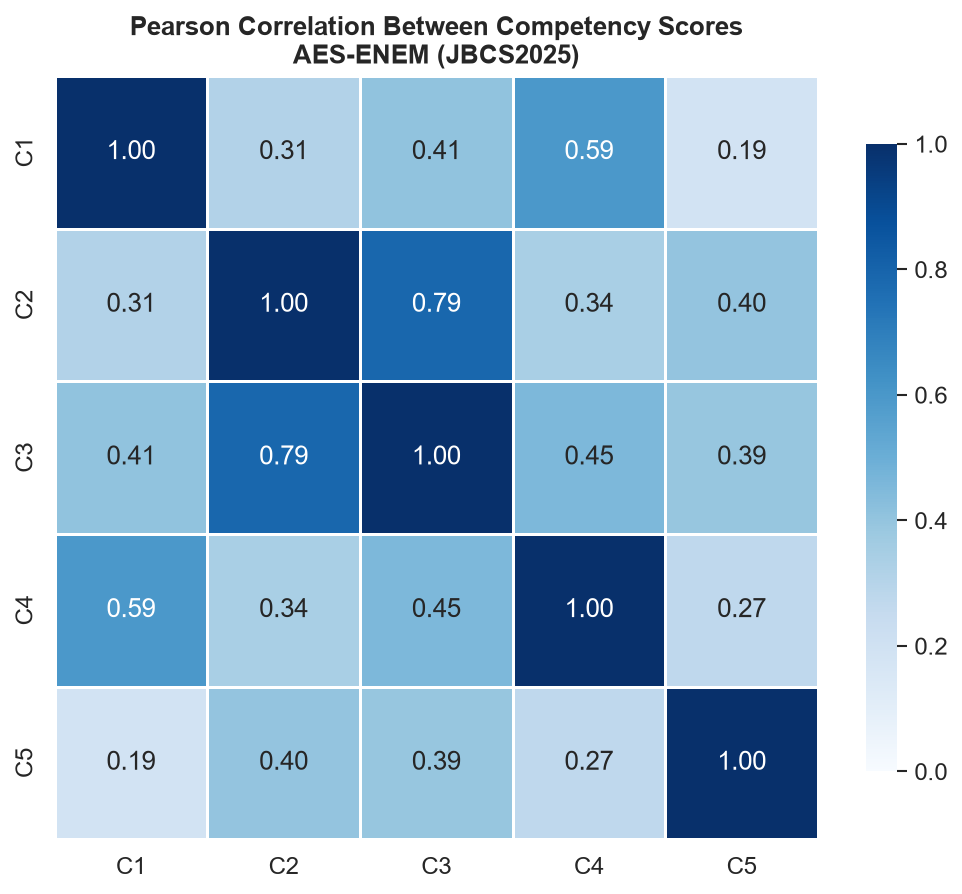

In [11]:
corr = df[COMP_LABELS].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    corr,
    annot=True, fmt=".2f",
    cmap="Blues", vmin=0, vmax=1,
    linewidths=0.5, square=True,
    cbar_kws={"shrink": 0.8},
    ax=ax,
)
ax.set_title("Pearson Correlation Between Competency Scores\nAES-ENEM (JBCS2025)",
             fontweight="bold")
plt.tight_layout()
_save("05_competency_correlation")
plt.show()

#### Number of essays per maximum possible score

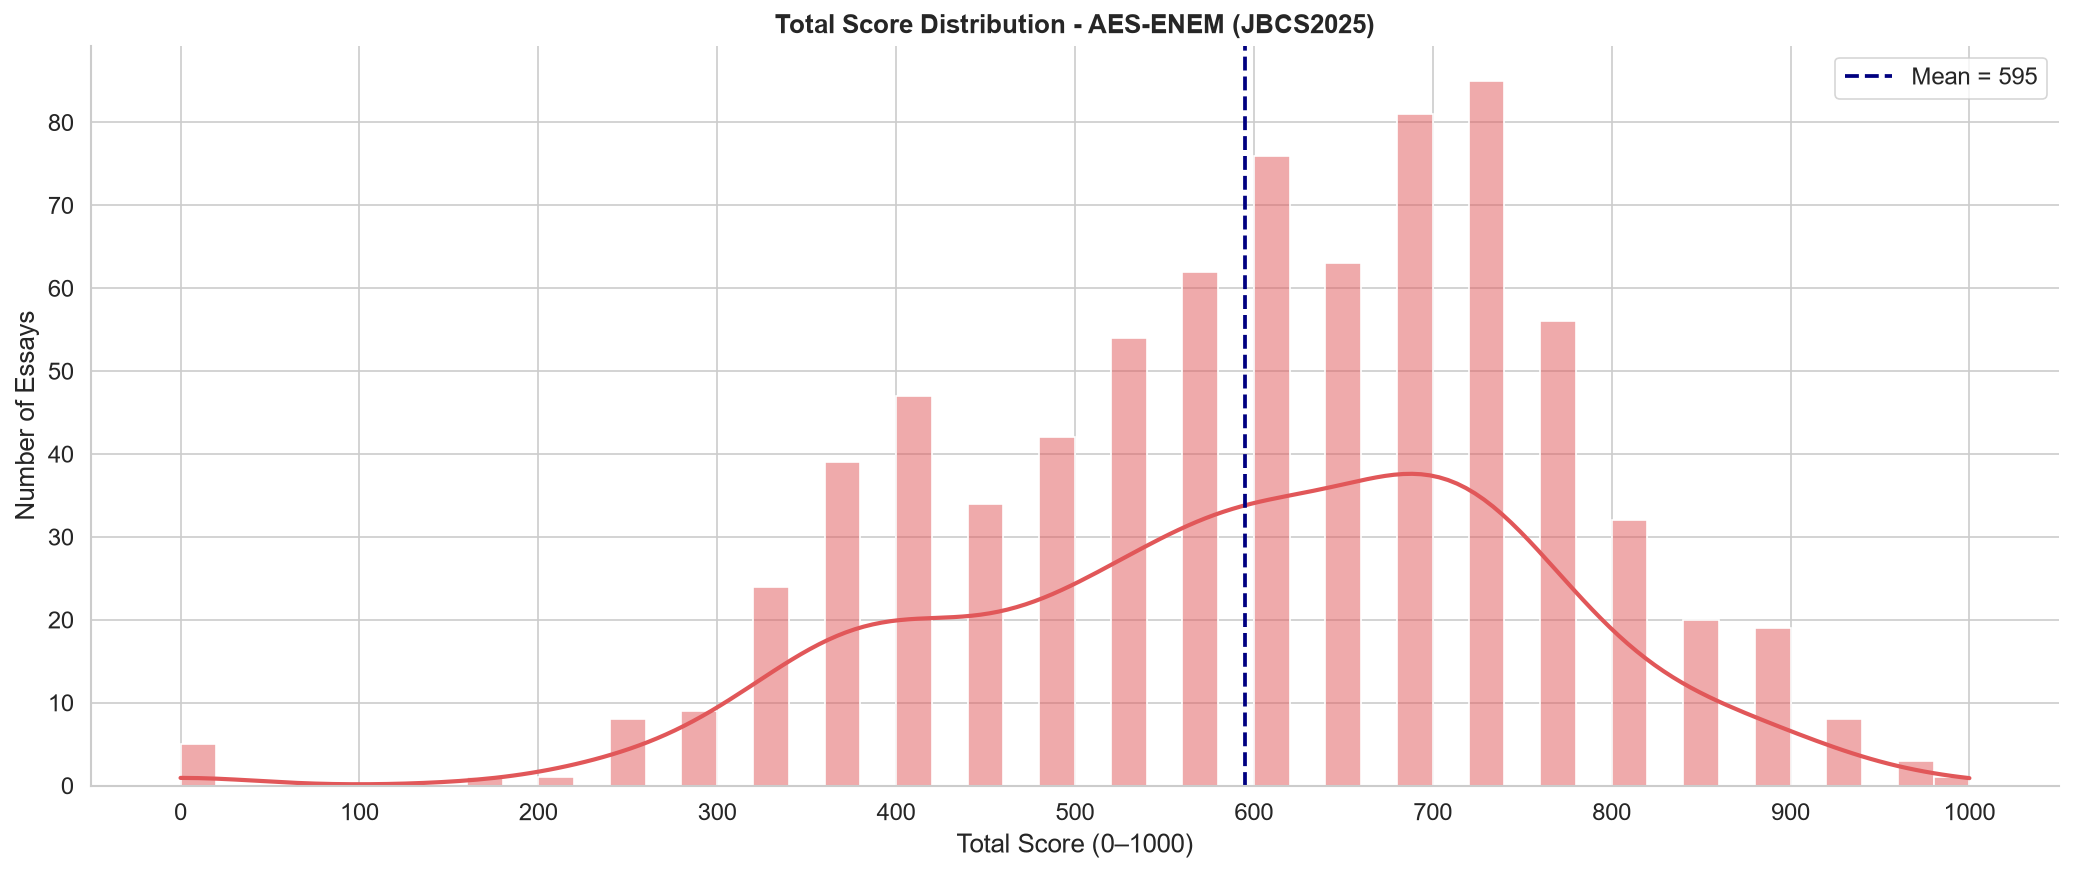

Mean   : 595.3
Median : 600.0
Std Dev: 163.6
Min / Max : 0 / 1000


In [12]:
bins = np.arange(0, 1020, 20)
mean_val = df["Total_Score"].mean()

fig, ax = plt.subplots(figsize=(14, 6))
sns.histplot(
    data=df, x="Total_Score",
    bins=bins,
    color=COMP_PALETTE[3],
    kde=True,
    line_kws={"linewidth": 2},
    ax=ax,
)
ax.axvline(mean_val, color="navy", linestyle="--", linewidth=1.8,
           label=f"Mean = {mean_val:.0f}")
ax.set_title("Total Score Distribution - AES-ENEM (JBCS2025)", fontweight="bold")
ax.set_xlabel("Total Score (0–1000)")
ax.set_ylabel("Number of Essays")
ax.set_xticks(range(0, 1001, 100))
ax.legend()
plt.tight_layout()
_save("06_total_score_distribution")
plt.show()

print(f"Mean   : {df['Total_Score'].mean():.1f}")
print(f"Median : {df['Total_Score'].median():.1f}")
print(f"Std Dev: {df['Total_Score'].std():.1f}")
print(f"Min / Max : {df['Total_Score'].min()} / {df['Total_Score'].max()}")

#### Token truncation analysis (BERTimbau-base)

In [13]:
print("Loading BERTimbau tokenizer...")
tokenizer = AutoTokenizer.from_pretrained("neuralmind/bert-base-portuguese-cased")

MAX_LEN = 512

df["token_count"] = df["essay_text"].apply(lambda t: len(tokenizer.encode(t, add_special_tokens=True)))
df["is_truncated"] = df["token_count"] > MAX_LEN
df["excess_tokens"] = (df["token_count"] - MAX_LEN).clip(lower=0)

n_trunc = int(df["is_truncated"].sum())
pct = n_trunc/len(df) * 100

print(f"Total essays     : {len(df):,}")
print(f"Truncated essays : {n_trunc:,}  ({pct:.2f}%)")
print(f"\nToken count statistics (all essays):")
print(df["token_count"].describe().round(1).to_string())

Loading BERTimbau tokenizer...
Total essays     : 770
Truncated essays : 50  (6.49%)

Token count statistics (all essays):
count    770.0
mean     338.9
std      110.7
min      112.0
25%      253.0
50%      321.0
75%      418.0
max      820.0


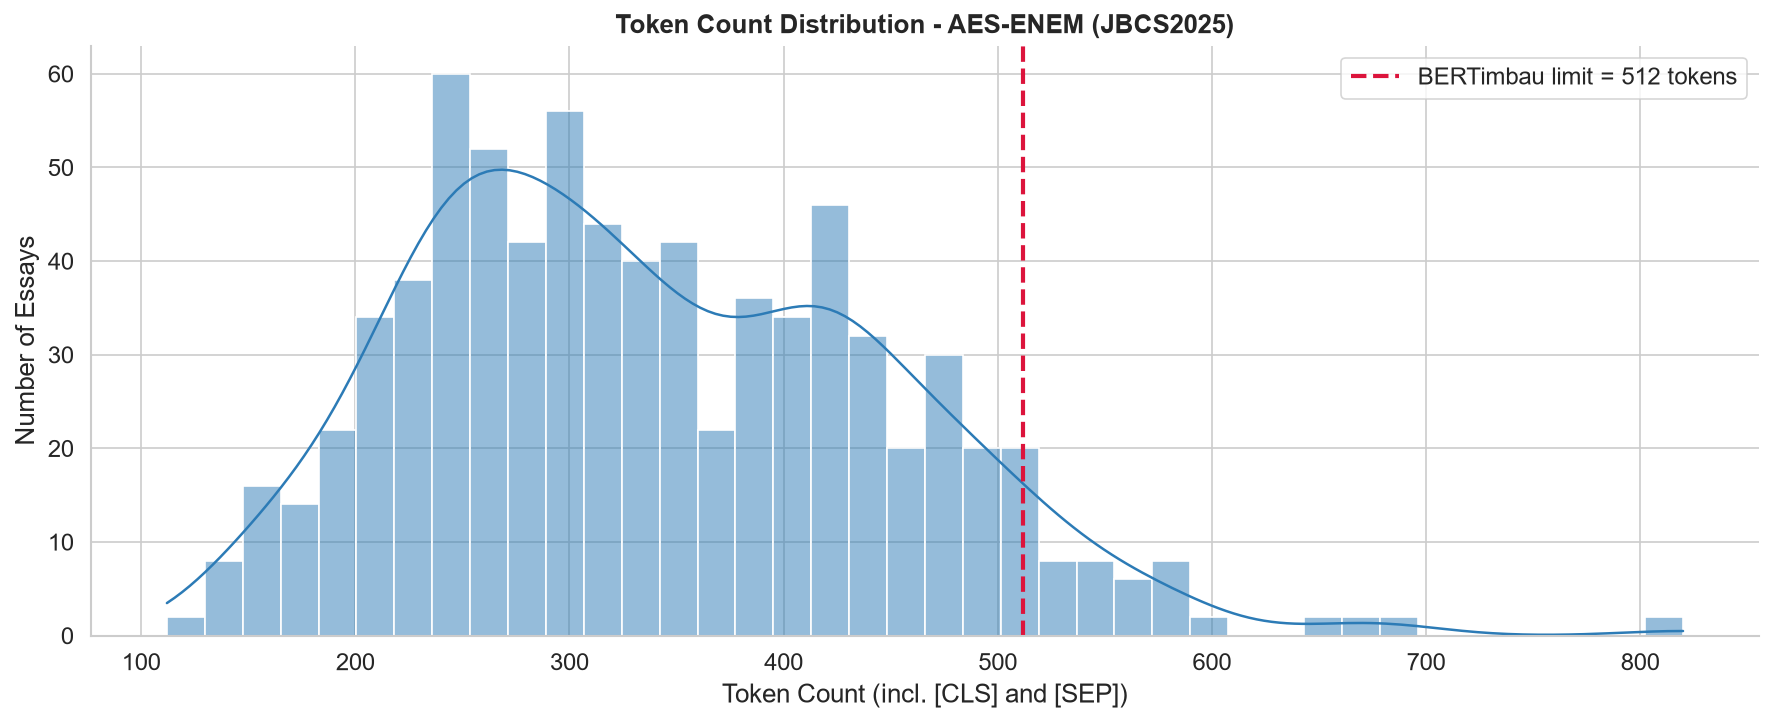

In [14]:
# Full token count distribution
fig, ax = plt.subplots(figsize=(12, 5))
sns.histplot(data=df, x="token_count", bins=40, color=PRIMARY_CLR, kde=True, ax=ax)
ax.axvline(MAX_LEN, color="crimson", linestyle="--", linewidth=2,
           label=f"BERTimbau limit = {MAX_LEN} tokens")
ax.set_title("Token Count Distribution - AES-ENEM (JBCS2025)", fontweight="bold")
ax.set_xlabel("Token Count (incl. [CLS] and [SEP])")
ax.set_ylabel("Number of Essays")
ax.legend()
plt.tight_layout()
_save("07a_token_count_dist")
plt.show()

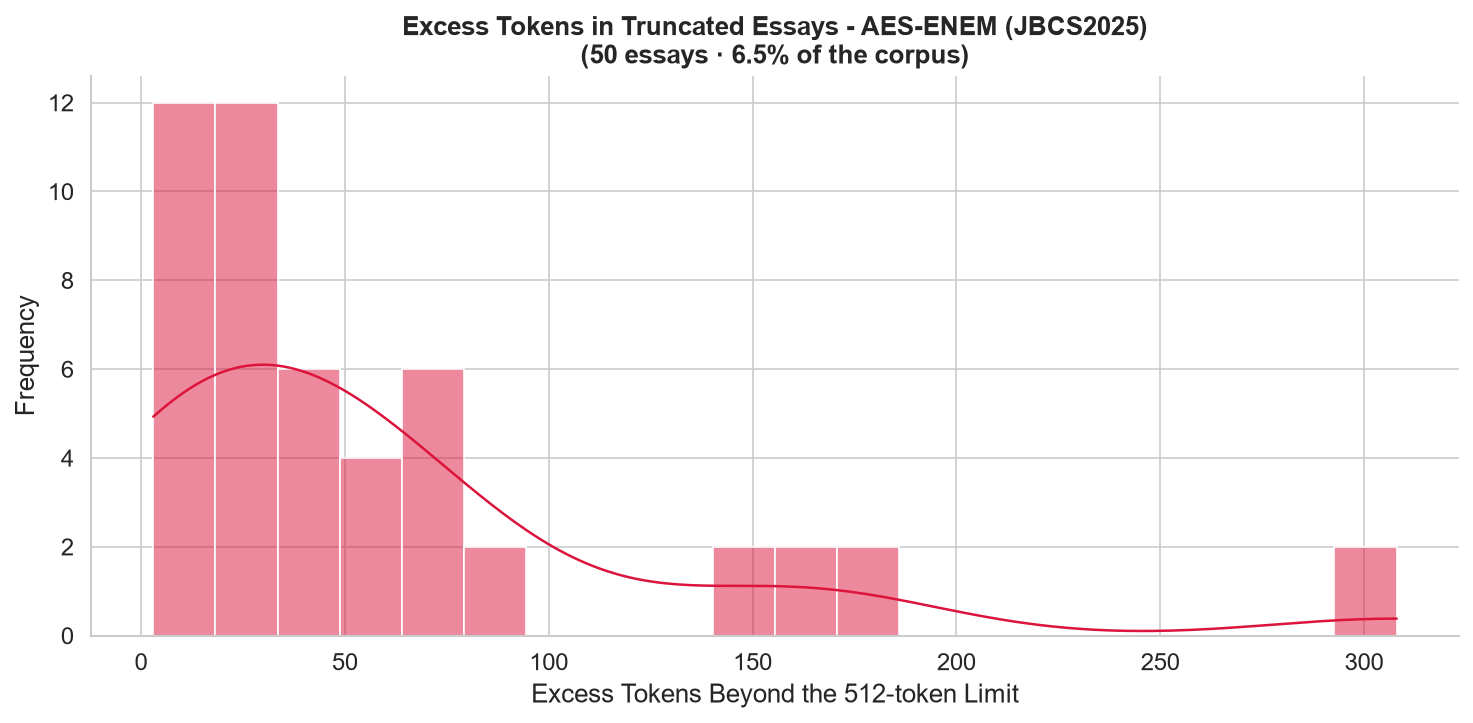

Excess token statistics (truncated essays only):
count     50.0
mean      60.2
std       69.8
min        3.0
25%       19.0
50%       35.0
75%       70.0
max      308.0


In [15]:
# Excess tokens among truncated essays
if n_trunc > 0:
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.histplot(
        data=df[df["is_truncated"]],
        x="excess_tokens",
        bins=20,
        color="crimson",
        kde=(n_trunc > 5),
        ax=ax,
    )
    ax.set_title(
        f"Excess Tokens in Truncated Essays - AES-ENEM (JBCS2025)\n"
        f"({n_trunc:,} essays · {pct:.1f}% of the corpus)",
        fontweight="bold",
    )
    ax.set_xlabel("Excess Tokens Beyond the 512-token Limit")
    ax.set_ylabel("Frequency")
    plt.tight_layout()
    _save("07b_excess_tokens")
    plt.show()

    print("Excess token statistics (truncated essays only):")
    print(df.loc[df["is_truncated"], "excess_tokens"].describe().round(1).to_string())
else:
    print("No truncated essays - all essays fit within 512 tokens.")